In [1]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import diffrax as dfx

from core.spacing import LinearSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import idx_phi, idx_lapse
from bssn.constraintsdiagnostic import get_constraints_diagnostic

In [2]:
A = 0.2
r0 = 3.0
sigma = 1.0

num_points = 201
r_max = 10.0

T = 6.0
num_output_times = 101
dt0 = 0.01

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)

spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx

In [3]:
def scalar_profile(r, amplitude, sigma):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)

scalar_profile_dr = jax.grad(scalar_profile, argnums=0)




In [4]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
    scalar_profile_dr,
    in_axes=(0, None, None),)(r_aux, amplitude, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

In [7]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = scalar_profile(
        r_physical, amplitude, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(psi_physical**2)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

In [8]:
initial_state = make_initial_state(A)

Ham, Mom = get_constraints_diagnostic(
    initial_state,
    jnp.array([0.0]),
    grid,
    background,
    matter,
)

# Exclude the ghost cells and the last two physical points,
# where the outer boundary can affect the finite-difference stencil.
interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(jnp.abs(Ham[0, interior]))
mom_error = jnp.max(
    jnp.linalg.norm(Mom[0, interior], axis=-1)
)

print("All initial-state values finite:",
      bool(jnp.all(jnp.isfinite(initial_state))))
print("All psi values positive:",
      bool(jnp.all(solve_psi(r_physical, dr, A, r0, sigma) > 0)))
print("Largest interior Hamiltonian constraint:", float(ham_error))
print("Largest interior momentum constraint:", float(mom_error))

All initial-state values finite: True
All psi values positive: True
Largest interior Hamiltonian constraint: 0.004425005216460602
Largest interior momentum constraint: 0.0


In [9]:
def evolve(amplitude):
    y0 = make_initial_state(amplitude)

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter)

    save_times = jnp.linspace(0.0, T, num_output_times)

    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(),
        t0=0.0,
        t1=T,
        dt0=dt0,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=dfx.SaveAt(ts=save_times),
        max_steps=700,
    )

    return solution

Minimum innermost physical lapse: 0.6347078344443283


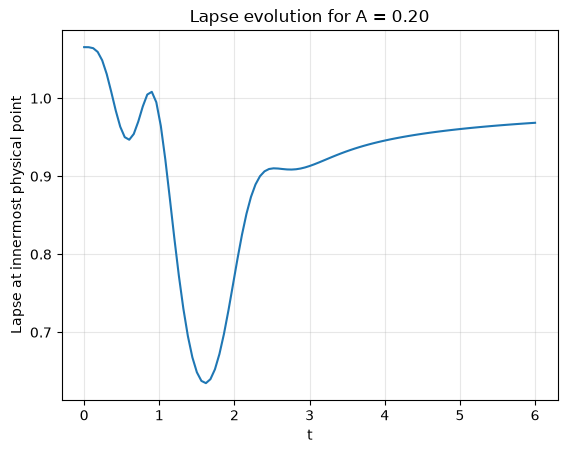

In [10]:
solution = evolve(A)

state_history = solution.ys.reshape(
    solution.ts.size,
    grid.NUM_VARS,
    grid.N,
)
lapse_history = state_history[:, idx_lapse, NUM_GHOSTS]

print("Minimum innermost physical lapse:",
      float(jnp.min(lapse_history)))

plt.plot(solution.ts, lapse_history)
plt.xlabel("t")
plt.ylabel("Lapse at innermost physical point")
plt.title(f"Lapse evolution for A = {A:.2f}")
plt.grid(alpha=0.3)
plt.show()

In [11]:
lapse_initial = state_history[0, idx_lapse]
lapse_final = state_history[-1, idx_lapse]

print("Maximum lapse change anywhere on grid:",
      float(jnp.max(jnp.abs(lapse_final - lapse_initial))))
print("Lapse change at innermost physical point:",
      float(lapse_final[NUM_GHOSTS] - lapse_initial[NUM_GHOSTS]))
print("Maximum change in the full state:",
      float(jnp.max(jnp.abs(solution.ys[-1] - solution.ys[0]))))

Maximum lapse change anywhere on grid: 0.0969911941482392
Lapse change at innermost physical point: -0.09699055208334872
Maximum change in the full state: 0.0969911941482392


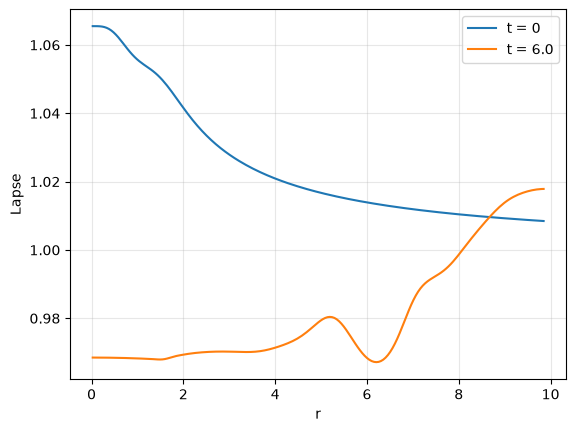

In [12]:
plt.plot(grid.r[physical], lapse_initial[physical], label="t = 0")
plt.plot(grid.r[physical], lapse_final[physical], label=f"t = {T}")
plt.xlabel("r")
plt.ylabel("Lapse")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Maximum scalar-field change: 0.0735398184753947


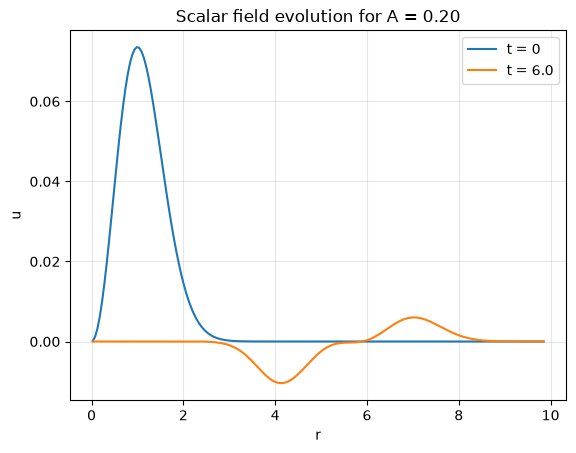

In [13]:
u_history = state_history[:, matter.idx_u, :]

print("Maximum scalar-field change:",
      float(jnp.max(jnp.abs(u_history[-1] - u_history[0]))))

plt.plot(grid.r[physical], u_history[0, physical], label="t = 0")
plt.plot(grid.r[physical], u_history[-1, physical], label=f"t = {T}")
plt.xlabel("r")
plt.ylabel("u")
plt.title(f"Scalar field evolution for A = {A:.2f}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Check that constraints are satisfied

In [14]:
Ham_history, Mom_history = get_constraints_diagnostic(
    solution.ys,
    solution.ts,
    grid,
    background,
    matter,
)

interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(
    jnp.abs(Ham_history[:, interior]),
    axis=1,
)
mom_error = jnp.max(
    jnp.linalg.norm(Mom_history[:, interior, :], axis=-1),
    axis=1,
)

print("Largest interior Hamiltonian constraint at t=0:",
      float(ham_error[0]))
print("Largest interior Hamiltonian constraint at t=6:",
      float(ham_error[-1]))
print("Largest interior momentum constraint at t=6:",
      float(mom_error[-1]))

Largest interior Hamiltonian constraint at t=0: 0.004425005216460602
Largest interior Hamiltonian constraint at t=6: 0.007713571970779208
Largest interior momentum constraint at t=6: 0.006894182388023981
